# VGG bit-flip campaign (week 3)
Per-layer, per-bit SDC and non-finite rates for the frozen VGG networks.

**Before starting:** Runtime → Change runtime type → **T4 GPU**. Run the cells one at a time, top to bottom.
Use the same GPU type for every campaign run.

## 1. Settings: edit these two lines

In [38]:
BRANCH = "main"                       # or "main" once week2 is merged
CIFAR_SRC = "/content/drive/MyDrive/aic_models/vgg_cifar10_fp32.pt"   # path to the shared CIFAR-10 file
FMNIST_SRC = "/content/drive/MyDrive/aic_models/vgg_fmnist_fp32.pt"

## 2. Check the GPU

In [18]:
!nvidia-smi

Sat Nov 28 02:29:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 3. Clone the repo and switch branch

In [19]:
from getpass import getpass
token = getpass("GitHub token: ")
%cd /content
!git clone https://{token}@github.com/AryanKpr/AIC-Research.git
%cd /content/AIC-Research
!git checkout {BRANCH}
!git config user.name "Your Name"
!git config user.email "your-github-email@example.com"
!git config core.editor true
!ls src

GitHub token: ··········
/content
fatal: destination path 'AIC-Research' already exists and is not an empty directory.
/content/AIC-Research
Already on 'main'
Your branch is up to date with 'origin/main'.
analyze_cnn.py	campaign_cnn.py  common.py  step4.py	  train.py
analyze.py	campaign.py	 faults.py  test_flip.py


Check that `faults.py`, `campaign_cnn.py` and `analyze_cnn.py` are listed. If not, push them from VS Code first and run `!git pull`.

## 4. Mount Drive and copy the frozen weights

In [20]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p models
!cp "{FMNIST_SRC}" models/vgg_fmnist_fp32.pt
!cp "{CIFAR_SRC}" models/vgg_cifar10_fp32.pt
!sha256sum models/*.pt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cp: cannot stat '/content/drive/MyDrive/vgg_cifar10_fp32.pt': No such file or directory
41bb17a5b5bc26b5cbcbcb3e80a9d43c807d05c8adf7425b284a171d8056765d  models/vgg_fmnist_fp32.pt


The hashes must start with **41bb17a5** (Fashion-MNIST) and **a60d257c** (CIFAR-10).

## 5. Verify against the recorded metadata

In [21]:
!grep weights_sha256 logs/train_vgg_fmnist.json logs/train_vgg_cifar10.json
!python src/check_cnn.py

grep: logs/train_vgg_fmnist.json: No such file or directory
grep: logs/train_vgg_cifar10.json: No such file or directory
python3: can't open file '/content/AIC-Research/src/check_cnn.py': [Errno 2] No such file or directory


Both lines must say `SHA ok`. An accuracy marked `DIFFERS` only means a different GPU type was used for training; note it and continue.

## 6. Quick test (a couple of minutes)

In [42]:
!python src/campaign_cnn.py vgg cifar10 test --n 2
!python src/analyze_cnn.py vgg cifar10 test

vgg_cifar10: golden FP16 accuracy 0.8937 (recorded at training: 0.8937)
  NOTE: differs from the training record, probably a different GPU type. Results are still valid; both runs of this campaign must use the same GPU type.
Sanity check passed on conv6: flip changes outputs, restore is exact
conv5     160/224 faults   ~0 min left
Done: 224 faults in /content/AIC-Research/logs/campaign_vgg_cifar10_test.csv
VGG on CIFAR-10: 224 faults, 7 layers, elements per layer: conv1 2, conv2 2, conv3 2, conv4 2, conv5 2, conv6 2, fc 2

Pooled over layers (layers weighted equally):
 bit    field  n  masked_k  SDC_k  non-finite_k
  15     sign 14         0     14             0
  14 exponent 14         0     13             1
  13 exponent 14         0     14             0
  12 exponent 14         0     14             0
  11 exponent 14         0     14             0
  10 exponent 14         1     13             0
   9 mantissa 14         3     11             0
   8 mantissa 14         3     11        

Check that the sanity check passed, then remove the test output:

In [43]:
!rm -f logs/campaign_vgg_cifar10_test* logs/summary_vgg_cifar10_test* configs/elements_vgg_cifar10_n2.json figures/vgg_cifar10_test*

## 7. Campaign: CIFAR-10
If the session disconnects, rerun cells 1–5, then this cell again: it resumes where it stopped.

In [44]:
!python src/campaign_cnn.py vgg cifar10 run1

vgg_cifar10: golden FP16 accuracy 0.8937 (recorded at training: 0.8937)
  NOTE: differs from the training record, probably a different GPU type. Results are still valid; both runs of this campaign must use the same GPU type.
Sanity check passed on conv6: flip changes outputs, restore is exact
conv1     160/11200 faults   ~25 min left
conv1     320/11200 faults   ~25 min left
conv1     480/11200 faults   ~25 min left
conv1     640/11200 faults   ~25 min left
conv1     800/11200 faults   ~25 min left
conv1     960/11200 faults   ~25 min left
conv1     1120/11200 faults   ~24 min left
conv1     1280/11200 faults   ~24 min left
conv1     1440/11200 faults   ~24 min left
conv1     1600/11200 faults   ~23 min left
conv2     1760/11200 faults   ~23 min left
conv2     1920/11200 faults   ~22 min left
conv2     2080/11200 faults   ~22 min left
conv2     2240/11200 faults   ~22 min left
conv2     2400/11200 faults   ~21 min left
conv2     2560/11200 faults   ~21 min left
conv2     2720/11200 fau

Back up the result straight away:

In [45]:
!mkdir -p /content/drive/MyDrive/aic_results && cp logs/campaign_vgg_cifar10_run1* /content/drive/MyDrive/aic_results/

## 8. Campaign: Fashion-MNIST

In [46]:
!python src/campaign_cnn.py vgg fmnist run1

vgg_fmnist: golden FP16 accuracy 0.9376 (recorded at training: 0.9376)
  NOTE: differs from the training record, probably a different GPU type. Results are still valid; both runs of this campaign must use the same GPU type.
Sanity check passed on conv6: flip changes outputs, restore is exact
conv1     160/11200 faults   ~22 min left
conv1     320/11200 faults   ~22 min left
conv1     480/11200 faults   ~21 min left
conv1     640/11200 faults   ~21 min left
conv1     800/11200 faults   ~20 min left
conv1     960/11200 faults   ~20 min left
conv1     1120/11200 faults   ~20 min left
conv1     1280/11200 faults   ~19 min left
conv1     1440/11200 faults   ~19 min left
conv1     1600/11200 faults   ~19 min left
conv2     1760/11200 faults   ~18 min left
conv2     1920/11200 faults   ~18 min left
conv2     2080/11200 faults   ~18 min left
conv2     2240/11200 faults   ~17 min left
conv2     2400/11200 faults   ~17 min left
conv2     2560/11200 faults   ~17 min left
conv2     2720/11200 faul

In [ ]:
# !cp logs/campaign_vgg_fmnist_run1* /content/drive/MyDrive/aic_results/

## 9. Reproducibility check (same GPU type)
Rerun one campaign and compare the files. The two hashes must be identical.

In [3]:
"""
!python src/campaign_cnn.py vgg cifar10 run2
!sha256sum logs/campaign_vgg_cifar10_run1.csv logs/campaign_vgg_cifar10_run2.csv
!grep -E '"device"|"commit"|uncommitted' logs/campaign_vgg_cifar10_run1_meta.json logs/campaign_vgg_cifar10_run2_meta.json
"""

'\n!python src/campaign_cnn.py vgg cifar10 run2\n!sha256sum logs/campaign_vgg_cifar10_run1.csv logs/campaign_vgg_cifar10_run2.csv\n!grep -E \'"device"|"commit"|uncommitted\' logs/campaign_vgg_cifar10_run1_meta.json logs/campaign_vgg_cifar10_run2_meta.json\n'

## 10. Analyze

In [7]:
!python src/analyze_cnn.py vgg cifar10 run1
!python src/analyze_cnn.py vgg fmnist run1

VGG on CIFAR-10: 11200 faults, 7 layers, elements per layer: conv1 100, conv2 100, conv3 100, conv4 100, conv5 100, conv6 100, fc 100

Pooled over layers (layers weighted equally):
 bit    field   n  masked_k  SDC_k  non-finite_k
  15     sign 700        59    641             0
  14 exponent 700         0    672            28
  13 exponent 700        40    660             0
  12 exponent 700        35    665             0
  11 exponent 700        59    641             0
  10 exponent 700        86    614             0
   9 mantissa 700       136    564             0
   8 mantissa 700       179    521             0
   7 mantissa 700       230    470             0
   6 mantissa 700       260    440             0
   5 mantissa 700       306    394             0
   4 mantissa 700       347    353             0
   3 mantissa 700       388    312             0
   2 mantissa 700       421    279             0
   1 mantissa 700       455    245             0
   0 mantissa 700       497    203 

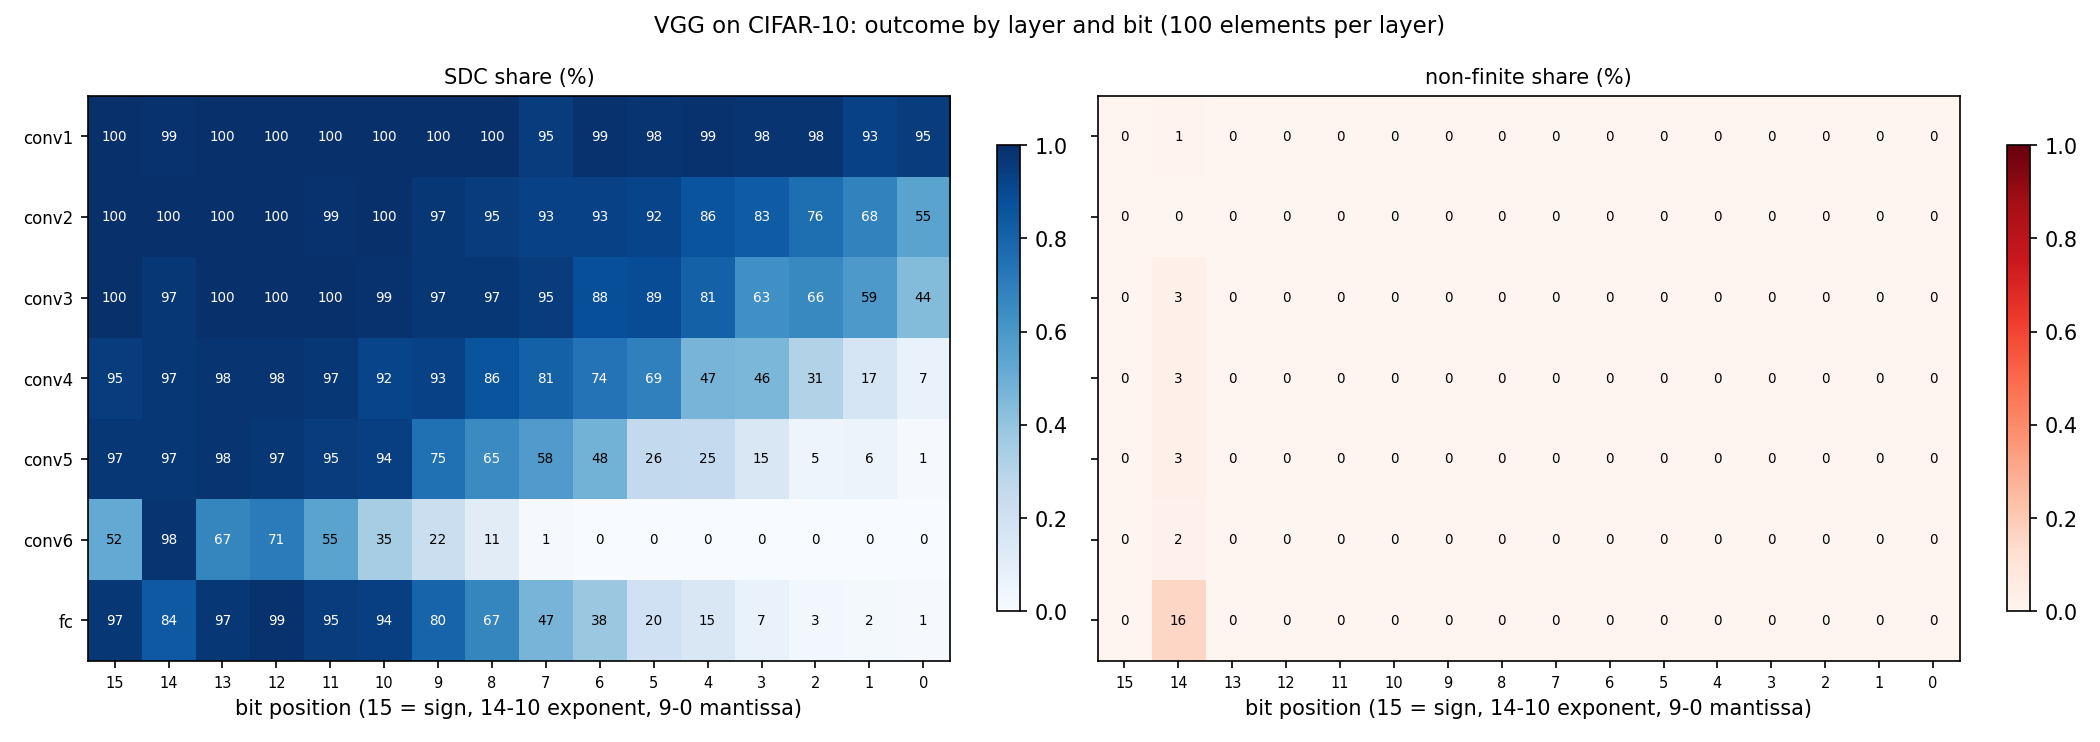

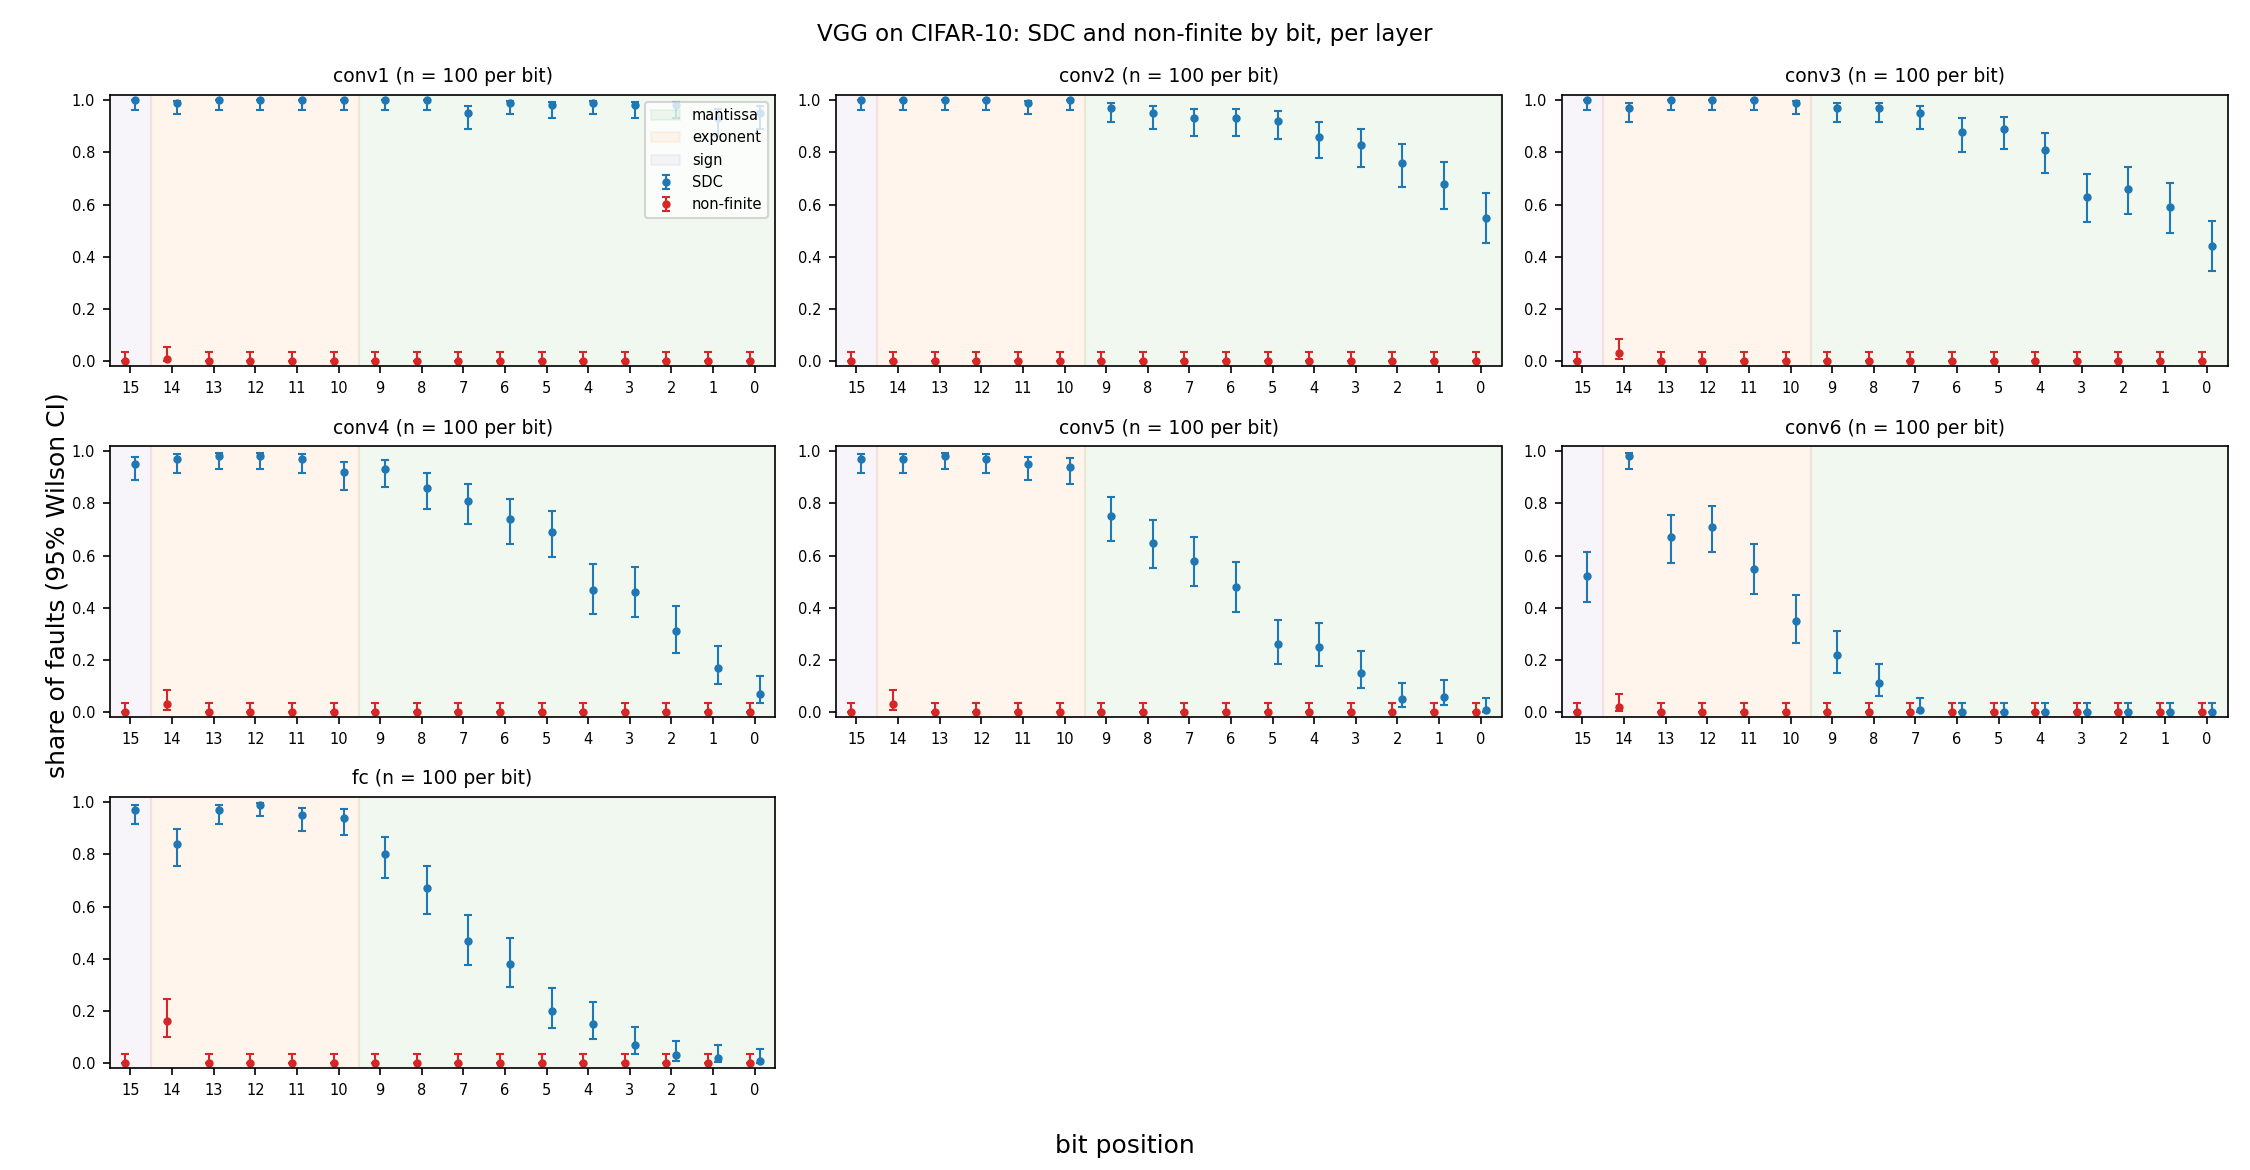

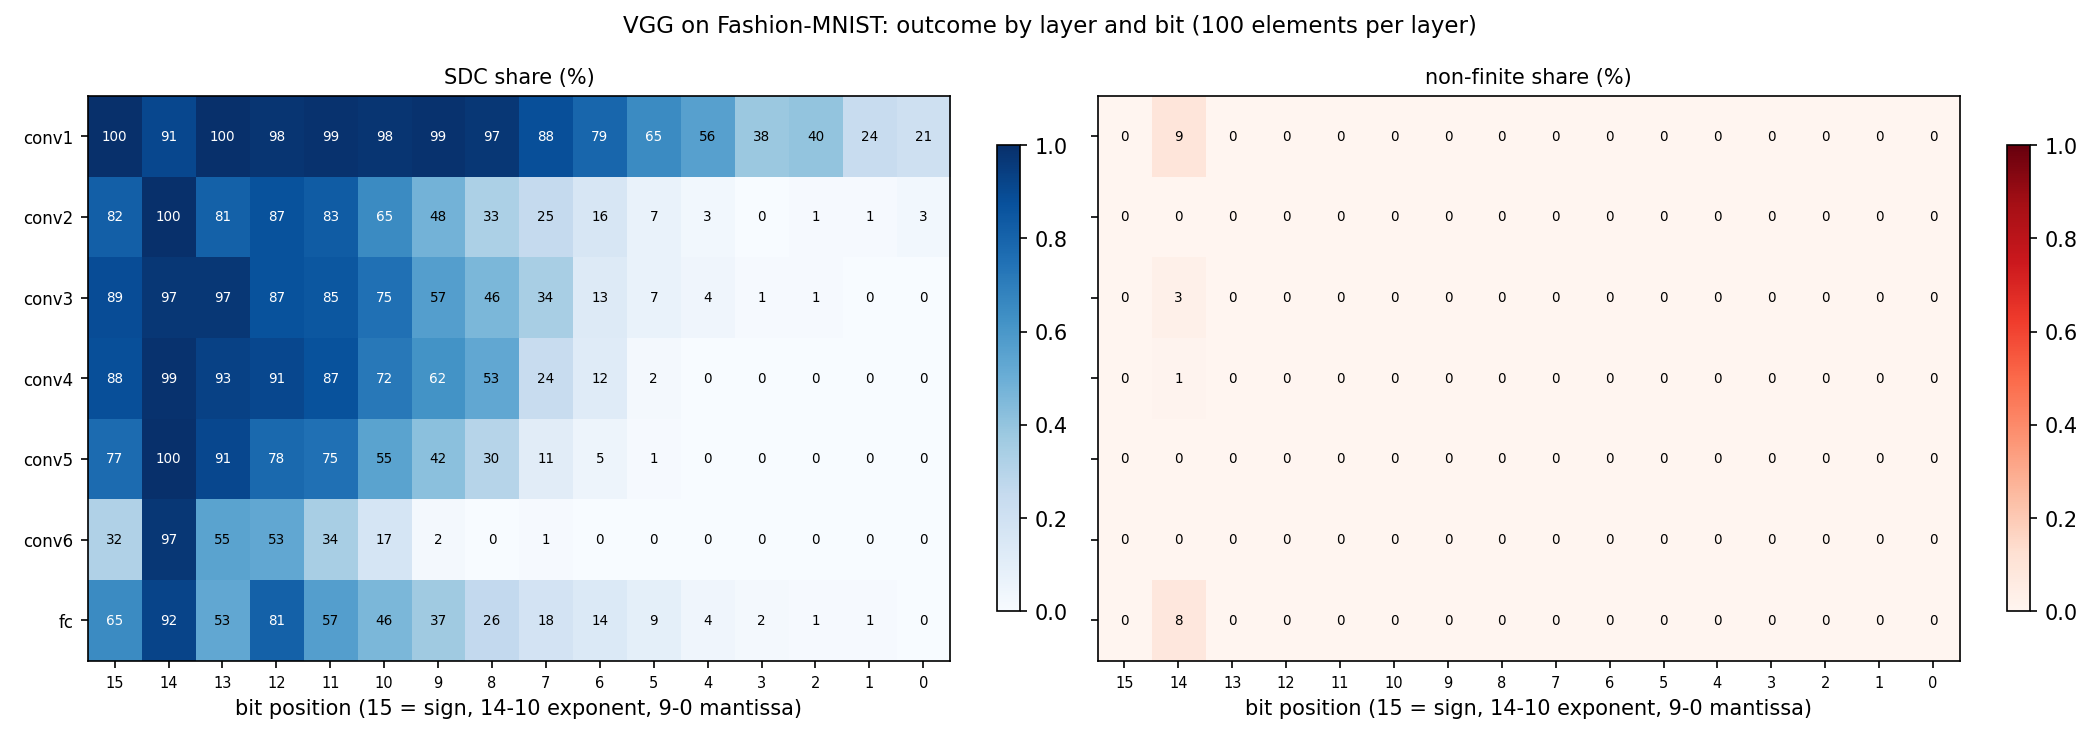

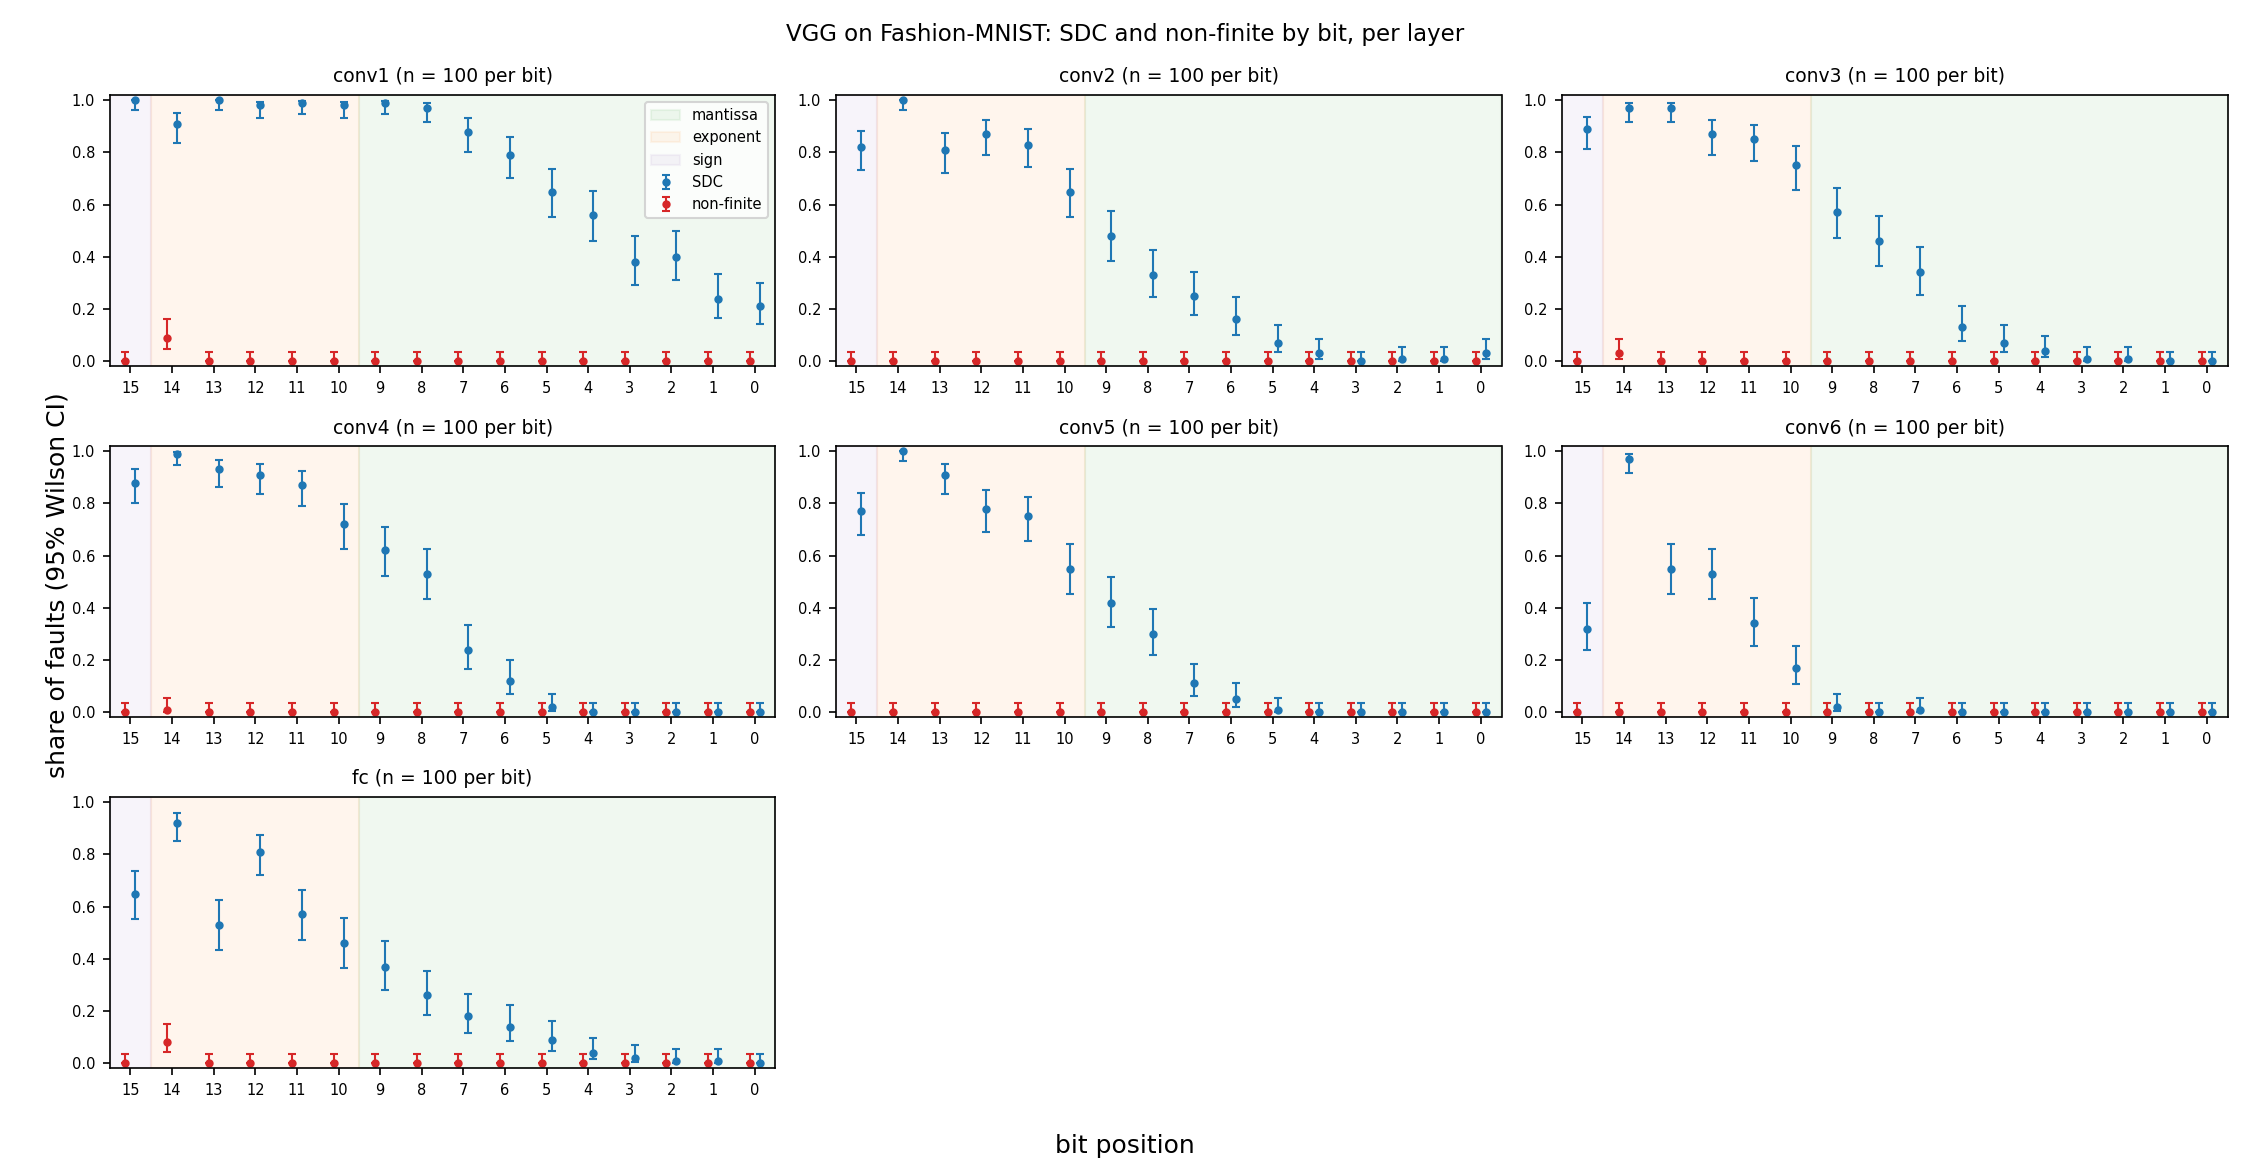

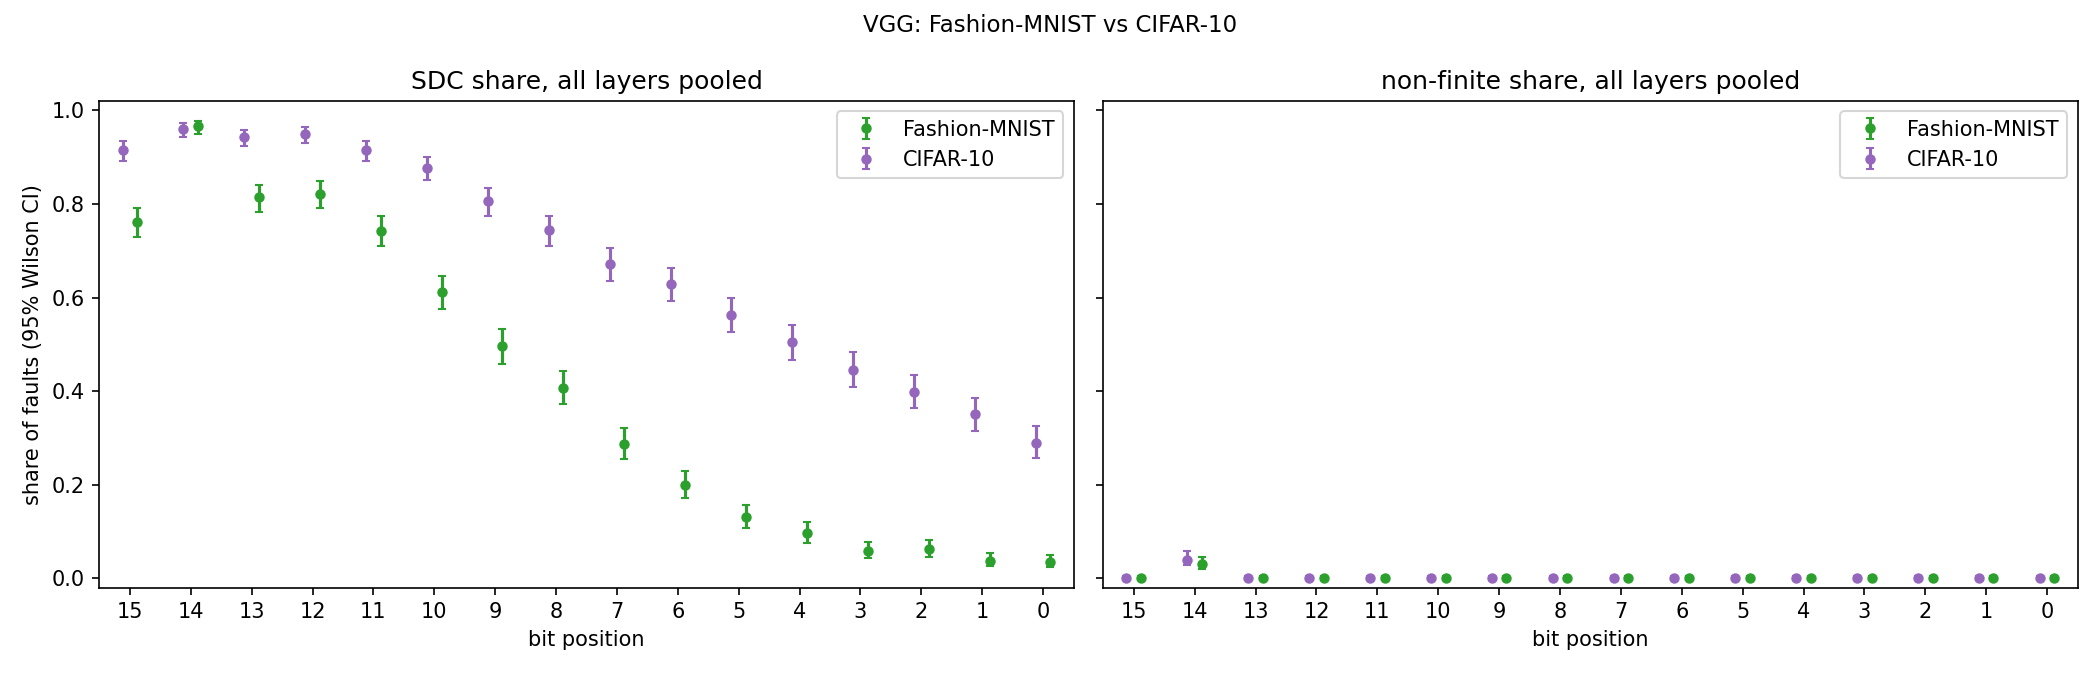

In [8]:
from IPython.display import Image, display
for f in ["vgg_cifar10_run1_heatmap", "vgg_cifar10_run1_layers", "vgg_fmnist_run1_heatmap",
          "vgg_fmnist_run1_layers", "vgg_compare_run1"]:
    display(Image(f"figures/{f}.png"))

In [9]:
import os; os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import sys; sys.path.insert(0, "src")
import torch
from check_cnn import load_trained
from data import test_tensors, EVAL_BATCH
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

for d in ["cifar10", "fmnist"]:
    model, _ = load_trained("vgg", d)
    X, _ = test_tensors(d); X = X.to("cuda", torch.float16)
    with torch.no_grad():
        runs = [torch.cat([model(X[i:i + EVAL_BATCH]) for i in range(0, len(X), EVAL_BATCH)]) for _ in range(5)]
    top2 = runs[0].float().topk(2, dim=1).values
    gap = top2[:, 0] - top2[:, 1]
    print(d, "| identical over 5 runs:", all(torch.equal(runs[0], r) for r in runs[1:]),
          "| top-2 exactly tied:", int((gap == 0).sum()), "| gap < 0.01:", int((gap < 0.01).sum()))

cifar10 | identical over 5 runs: True | top-2 exactly tied: 0 | gap < 0.01: 14
fmnist | identical over 5 runs: True | top-2 exactly tied: 1 | gap < 0.01: 9


In [10]:
import pandas as pd
for d in ["cifar10", "fmnist"]:
    df = pd.read_csv(f"logs/campaign_vgg_{d}_run1.csv")
    sdc = df[df["class"] == "SDC"]
    print(f"\n{d}: number of changed predictions per SDC fault (5 = 5 or more)")
    print(pd.crosstab(sdc.bit, sdc.changed.clip(upper=5)).sort_index(ascending=False))


cifar10: number of changed predictions per SDC fault (5 = 5 or more)
changed  1.0  2.0  3.0  4.0  5.0
bit                             
15        56   56   40   37  452
14         2    2    5    3  660
13        58   69   61   42  430
12        36   31   33   11  554
11        71   62   40   51  417
10       110   85   60   54  305
9        131  113   78   46  196
8        166  133   66   36  120
7        140  156   77   36   61
6        150  141   89   28   32
5        167  128   71   13   15
4        170  122   55    4    2
3        145  112   53    2    0
2        122  107   48    2    0
1        121   89   35    0    0
0        101   74   28    0    0

fmnist: number of changed predictions per SDC fault (5 = 5 or more)
changed  1.0  2.0  3.0  4.0  5.0
bit                             
15        89   50   54   29  311
14         7    9    2    3  655
13        99   55   45   45  326
12        52   16   11   13  483
11        86   52   50   48  284
10       117   54   48   22  187
9  

## 11. Commit and push the results

In [11]:
!git add logs configs
!git add -f figures/*.png
!git status
!git commit -m "VGG campaigns: per-layer, per-bit results"
!git push

On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   figures/vgg_cifar10_run1_bits.png
	new file:   figures/vgg_cifar10_run1_layers.png
	new file:   figures/vgg_compare_run1.png
	new file:   figures/vgg_fmnist_run1_bits.png
	new file:   figures/vgg_fmnist_run1_layers.png

[main 1395b56] VGG campaigns: per-layer, per-bit results
 5 files changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 figures/vgg_cifar10_run1_bits.png
 create mode 100644 figures/vgg_cifar10_run1_layers.png
 create mode 100644 figures/vgg_compare_run1.png
 create mode 100644 figures/vgg_fmnist_run1_bits.png
 create mode 100644 figures/vgg_fmnist_run1_layers.png
Enumerating objects: 10, done.
Counting objects: 100% (10/10), done.
Delta compression using up to 2 threads
Compressing objects: 100% (8/8), done.
Writing objects: 100% (8/8), 319.11 KiB | 11.82 MiB/s, done.
Total 8 (delta 1), reused 0 (delta 0), pack-r

In [12]:
!python src/campaign_cnn.py vgg cifar10 run2

vgg_cifar10: golden FP16 accuracy 0.8937 (recorded at training: 0.8937)
  NOTE: differs from the training record, probably a different GPU type. Results are still valid; both runs of this campaign must use the same GPU type.
Sanity check passed on conv6: flip changes outputs, restore is exact
Resuming: 5496 faults already in /content/AIC-Research/logs/campaign_vgg_cifar10_run2.csv
Traceback (most recent call last):
  File "/content/AIC-Research/src/campaign_cnn.py", line 134, in <module>
    finite, preds = evaluate()
                    ~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/_contextlib.py", line 124, in decorate_context
    return func(*args, **kwargs)
  File "/content/AIC-Research/src/campaign_cnn.py", line 83, in evaluate
    return bool(torch.isfinite(out).all()), out.argmax(1)
           ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
KeyboardInterrupt


In [13]:
!n=$(wc -l < logs/campaign_vgg_cifar10_run2.csv); head -n $n logs/campaign_vgg_cifar10_run1.csv | cmp - logs/campaign_vgg_cifar10_run2.csv && echo "first $n lines identical"
!awk -F, 'NF!=10 {print "line " NR " has " NF " fields"}' logs/campaign_vgg_cifar10_run2.csv | head

first 9934 lines identical


In [14]:
!python src/campaign_cnn.py vgg cifar10 run2

vgg_cifar10: golden FP16 accuracy 0.8937 (recorded at training: 0.8937)
  NOTE: differs from the training record, probably a different GPU type. Results are still valid; both runs of this campaign must use the same GPU type.
Sanity check passed on conv6: flip changes outputs, restore is exact
Resuming: 9933 faults already in /content/AIC-Research/logs/campaign_vgg_cifar10_run2.csv
Done: 11200 faults in /content/AIC-Research/logs/campaign_vgg_cifar10_run2.csv


In [15]:
!sha256sum logs/campaign_vgg_cifar10_run1.csv logs/campaign_vgg_cifar10_run2.csv
!grep -E '"device"|"commit"|uncommitted' logs/campaign_vgg_cifar10_run1_meta.json logs/campaign_vgg_cifar10_run2_meta.json

484f00d5ff34f161cf650046cb9e4bde1ad1b962e89b6c4b3362b0eb74afbde6  logs/campaign_vgg_cifar10_run1.csv
484f00d5ff34f161cf650046cb9e4bde1ad1b962e89b6c4b3362b0eb74afbde6  logs/campaign_vgg_cifar10_run2.csv
logs/campaign_vgg_cifar10_run1_meta.json:  "device": "Tesla T4",
logs/campaign_vgg_cifar10_run1_meta.json:  "commit": "ecd7cdc437d24ee74bcd3b5388ae1a729f6f4452",
logs/campaign_vgg_cifar10_run1_meta.json:  "uncommitted_changes": false
logs/campaign_vgg_cifar10_run2_meta.json:  "device": "Tesla T4",
logs/campaign_vgg_cifar10_run2_meta.json:  "commit": "1395b560349302e01185e49e9aea1b4b1ac09b44",
logs/campaign_vgg_cifar10_run2_meta.json:  "uncommitted_changes": false


In [16]:
!git add logs/campaign_vgg_cifar10_run2*
!git commit -m "VGG CIFAR-10 run2: identical to run1 (484f00d5...)"
!git push

[main 8bdb162] VGG CIFAR-10 run2: identical to run1 (484f00d5...)
 2 files changed, 5762 insertions(+)
 create mode 100644 logs/campaign_vgg_cifar10_run2_meta.json
Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 838 bytes | 838.00 KiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/AryanKpr/AIC-Research.git
   1395b56..8bdb162  main -> main


## 12. Save this notebook
Edit → Clear all outputs, check for `ghp_` / `github_pat_` with Find, then File → Download .ipynb
and commit it to `notebooks/` from VS Code.

In [32]:
!git branch --show-current
!ls src

main
analyze_cnn.py	campaign_cnn.py  common.py  step4.py	  train.py
analyze.py	campaign.py	 faults.py  test_flip.py


In [33]:
!git pull
!ls src
!python src/check_cnn.py

remote: Enumerating objects: 10, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 4 (delta 3), reused 4 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 566 bytes | 566.00 KiB/s, done.
From https://github.com/AryanKpr/AIC-Research
   7a5e32e..ecd7cdc  main       -> origin/main
Updating 7a5e32e..ecd7cdc
Fast-forward
 .DS_Store                   | Bin 10244 -> 0 bytes
 .gitignore                  |   1 +
 logs/train_vgg_cifar10.json |  66 +++++++++++++++++++++++
 logs/train_vgg_fmnist.json  |  62 +++++++++++++++++++++
 src/check_cnn.py            |  47 ++++++++++++++++
 src/data.py                 |  53 ++++++++++++++++++
 src/models.py               |  88 ++++++++++++++++++++++++++++++
 src/seeds.py                |  29 ++++++++++
 src/train_cnn.py            | 128 ++++++++++++++++++++++++++++++++++++++++++++
 9 files changed, 474 insertions(+)
 delete mode 100644 .DS_Store
 create mode 100644 logs/train_vgg_c

In [34]:
!ls -la models/

total 1152
drwxr-xr-x  2 root root    4096 Nov 28 02:26 .
drwxr-xr-x 10 root root    4096 Nov 28 02:30 ..
-rw-------  1 root root 1168209 Nov 28 02:29 vgg_fmnist_fp32.pt


In [35]:
!find /content/drive/MyDrive -name "*.pt" 2>/dev/null

/content/drive/MyDrive/mlp_fp32.pt
/content/drive/MyDrive/aic_models/vgg_fmnist_fp32.pt


In [36]:
from google.colab import drive
drive.mount("/content/drive", force_remount=True)
!ls -la /content/drive/MyDrive/aic_models/

Mounted at /content/drive
total 2293
drwx------ 2 root root    4096 Nov 22 20:35 .
drwx------ 3 root root    4096 Nov 28 02:38 ..
-rw------- 1 root root 1170557 Nov 28 02:36 vgg_cifar10_fp32.pt
-rw------- 1 root root 1168209 Nov 19 03:53 vgg_fmnist_fp32.pt


In [40]:
!mkdir -p models
!cp "{FMNIST_SRC}" models/vgg_fmnist_fp32.pt
!cp "{CIFAR_SRC}" models/vgg_cifar10_fp32.pt
!sha256sum models/vgg_*.pt

a60d257c4d2e68ac4531edc44b66eb6351f1d6a93ff80edd132141f4fba4a288  models/vgg_cifar10_fp32.pt
41bb17a5b5bc26b5cbcbcb3e80a9d43c807d05c8adf7425b284a171d8056765d  models/vgg_fmnist_fp32.pt


In [41]:
!python src/check_cnn.py

vgg       cifar10   SHA ok  acc_fp32 0.8938 (matches)  acc_fp16 0.8937 (matches)
100% 26.4M/26.4M [00:01<00:00, 13.8MB/s]
100% 29.5k/29.5k [00:00<00:00, 202kB/s]
100% 4.42M/4.42M [00:01<00:00, 3.80MB/s]
100% 5.15k/5.15k [00:00<00:00, 37.3MB/s]
vgg       fmnist    SHA ok  acc_fp32 0.9375 (matches)  acc_fp16 0.9376 (matches)


In [1]:
%cd /content/AIC-Research
!ls -la logs/ models/
!git add logs/campaign_vgg_* configs/
!git commit -m "VGG campaigns run1: Fashion-MNIST and CIFAR-10"
!git push

/content/AIC-Research
logs/:
total 3196
drwxr-xr-x  2 root root    4096 Nov 28 03:43 .
drwxr-xr-x 10 root root    4096 Nov 28 02:30 ..
-rw-r--r--  1 root root  326213 Nov 28 02:25 campaign_run1.csv
-rw-r--r--  1 root root     292 Nov 28 02:25 campaign_run1_meta.json
-rw-r--r--  1 root root  326213 Nov 28 02:25 campaign_run2.csv
-rw-r--r--  1 root root     292 Nov 28 02:25 campaign_run2_meta.json
-rw-r--r--  1 root root 1002632 Nov 28 03:08 campaign_vgg_cifar10_run1.csv
-rw-r--r--  1 root root    1277 Nov 28 03:08 campaign_vgg_cifar10_run1_meta.json
-rw-r--r--  1 root root  492608 Nov 28 03:43 campaign_vgg_cifar10_run2.csv
-rw-r--r--  1 root root 1021143 Nov 28 03:30 campaign_vgg_fmnist_run1.csv
-rw-r--r--  1 root root    1276 Nov 28 03:30 campaign_vgg_fmnist_run1_meta.json
-rw-r--r--  1 root root     745 Nov 28 02:25 step4.csv
-rw-r--r--  1 root root     276 Nov 28 02:25 step4_meta.json
-rw-r--r--  1 root root    2736 Nov 28 03:43 summary_vgg_cifar10_run1_bit.csv
-rw-r--r--  1 root roo

In [6]:
%cd /content/AIC-Research
!git pull --no-edit
!grep -n "def yerr" src/analyze_cnn.py

/content/AIC-Research
remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (10/10), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 6 (delta 4), reused 6 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 866 bytes | 433.00 KiB/s, done.
From https://github.com/AryanKpr/AIC-Research
   0e28e4d..86d3c0b  main       -> origin/main
Updating 0e28e4d..86d3c0b
Fast-forward
 src/analyze_cnn.py | 11 +++++++++--
 1 file changed, 9 insertions(+), 2 deletions(-)
51:def yerr(s, cls):
